In [8]:
import numpy as np
import sys,os
os.environ["JAX_ENABLE_X64"] = "true"

sys.path.append('../../')
os.environ["JAX_PLATFORMS"] = "cpu"
import matplotlib.pyplot as plt
import jax 
from jax import numpy as jnp
from dadapy import MetricComparisons

In [28]:
def L2_distance(x, y):
    u = (x-y)
    return jnp.sqrt(jnp.sum(u*u))

for _ in range(1):
  Ns = 2000
  X = np.random.normal(size=(Ns, 3))
  Y = X[:,1:]
  X = X[:,:2]
  # print(f'{X.shape=}')
  # print(f'{Y.shape=}')

  from information_imbalance_module import build_information_imbalance as reff
  key_distances = jax.random.key(42)
  k = 1
  key_distances, subkey_distances = jax.random.split(key_distances)
  refff = reff(key=subkey_distances, 
              sample_size=Ns, 
              distance_fn=L2_distance, 
              k=k)
  X  = X[np.random.permutation(X.shape[0])]
  aux = refff(X,Y)
  print(f'{aux=}')

aux=(Array(1.06, dtype=float64), Array(1.02, dtype=float64))


In [18]:
from geometry import build_get_ranks,build_information_imbalance

get_ranks = build_get_ranks(key=subkey_distances, 
                            sample_size=Ns, 
                            distance_fn=L2_distance, 
                            )
x_ranks,y_ranks = get_ranks(X,Y)
print(f'{x_ranks.shape=}')
print(f'{y_ranks.shape=}')
np.savez("ranks.npz", x_ranks=x_ranks, y_ranks=y_ranks)
del x_ranks,y_ranks

x_ranks, y_ranks = np.load("ranks.npz").values()
II_fn = build_information_imbalance(k=1)
II_fn(x_ranks,y_ranks)

x_ranks.shape=(400, 1600)
y_ranks.shape=(400, 1600)


(Array(0.59, dtype=float64), Array(0.52, dtype=float64))

In [20]:
Ns = 2000
X = np.random.normal(size=(Ns, 4))
Y = X[:,1:]
X = X[:,:2+1]
print(f'{X.shape=}')
print(f'{Y.shape=}')

from information_imbalance_module import build_information_imbalance as reff
key_distances = jax.random.key(42)
k = 1
key_distances, subkey_distances = jax.random.split(key_distances)
refff = reff(key=subkey_distances, 
            sample_size=Ns, 
            distance_fn=L2_distance, 
            k=k)
# X  = X[np.random.permutation(X.shape[0])]
aux = refff(X,Y)
print(f'{aux=}')

X.shape=(2000, 3)
Y.shape=(2000, 3)
aux=(Array(0.34, dtype=float64), Array(0.34, dtype=float64))


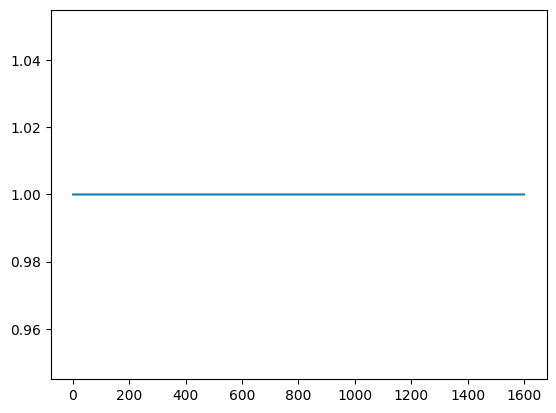

In [21]:
v,c = np.unique(x_ranks[0],return_counts=True)
plt.plot(v,c)
plt.show()